# Locally Linear Embedding (LLE)

## 1. Definition and intuition
LLE assumes each point and its nearby neighbors lie on a locally linear patch of a manifold. It first represents each point as a weighted reconstruction from its neighbors, then finds a low-dimensional embedding that preserves those reconstruction weights.

## 2. Optimization
For each point $x_i$, find weights $w_{ij}$ minimizing
$$
\left\|x_i-\sum_{j\in\mathcal N(i)}w_{ij}x_j\right\|^2,\quad
\sum_j w_{ij}=1.
$$
Then find low-dimensional coordinates $y_i$ minimizing
$$
\sum_i\left\|y_i-\sum_jw_{ij}y_j\right\|^2
$$
subject to centering and scale constraints. The matrix $M=(I-W)^T(I-W)$ gives an eigenproblem; the smallest eigenvector is the trivial constant solution and is discarded.

## 3. Why it works and assumptions
If manifold neighborhoods are approximately linear and the neighbor graph is appropriate, reconstruction weights can encode local geometry. LLE can fail when neighborhood size is wrong, samples are sparse, data contain noise, or local covariance matrices are poorly conditioned.

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt
from scipy.sparse import csr_matrix
from sklearn.datasets import make_swiss_roll
from sklearn.neighbors import NearestNeighbors
from sklearn.manifold import LocallyLinearEmbedding
from sklearn.metrics import pairwise_distances

SEED = 42
X, color = make_swiss_roll(n_samples=250, noise=0.04, random_state=SEED)


## 4. LLE from scratch

Nearest neighbors are found with a standard neighbor-search routine. Reconstruction weights and the final eigenproblem are computed explicitly. The dense matrix version is intended for small data.

In [2]:
def lle_scratch(X, n_neighbors=10, n_components=2, reg=1e-3):
    X = np.asarray(X, dtype=float)
    if X.ndim != 2 or len(X) <= n_neighbors or n_neighbors < 2:
        raise ValueError("Invalid X or n_neighbors")
    if not 1 <= n_components < X.shape[1] + 1 or reg <= 0:
        raise ValueError("Invalid n_components or reg")
    n, d = X.shape
    nbrs = NearestNeighbors(n_neighbors=n_neighbors+1).fit(X)
    inds = nbrs.kneighbors(X, return_distance=False)[:, 1:]
    W = np.zeros((n,n), dtype=float)
    for i in range(n):
        Z = X[inds[i]] - X[i]
        C = Z @ Z.T
        C += reg * np.trace(C if np.trace(C) > 0 else np.eye(n_neighbors)) * np.eye(n_neighbors)
        ones = np.ones(n_neighbors)
        try:
            w = np.linalg.solve(C, ones)
        except np.linalg.LinAlgError:
            w = np.linalg.lstsq(C, ones, rcond=None)[0]
        w /= w.sum()
        W[i, inds[i]] = w
    M = (np.eye(n)-W).T @ (np.eye(n)-W)
    vals, vecs = np.linalg.eigh((M+M.T)/2)
    order = np.argsort(vals)
    # First eigenvector is the constant vector; take the next n_components.
    emb = vecs[:, order[1:n_components+1]]
    return emb, vals[order], inds, W

Y_scratch, evals, inds, W = lle_scratch(X, n_neighbors=10, n_components=2)
print("Embedding shape:", Y_scratch.shape, "smallest eigenvalues:", np.round(evals[:5], 6))


Embedding shape: (250, 2) smallest eigenvalues: [-0.e+00  0.e+00  0.e+00  0.e+00  1.e-06]


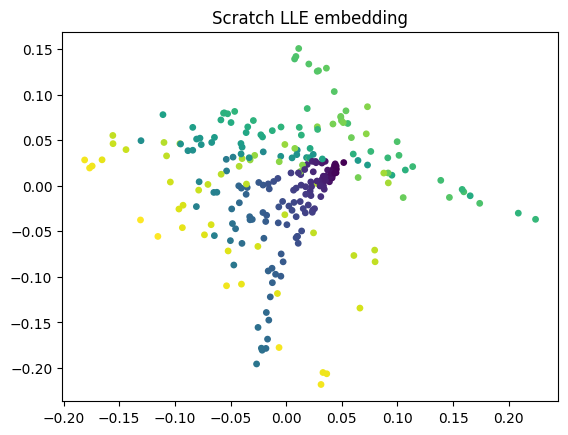

In [3]:
plt.scatter(Y_scratch[:,0], Y_scratch[:,1], c=color, cmap="viridis", s=15)
plt.title("Scratch LLE embedding"); plt.show()


## 5. Compare with scikit-learn

Coordinates can differ by sign, rotation or scale. We compare shape and finiteness rather than raw coordinate equality.

In [4]:
lle = LocallyLinearEmbedding(n_neighbors=10, n_components=2, method="standard",
                             eigen_solver="arpack", random_state=SEED)
Y_sk = lle.fit_transform(X)
print("sklearn reconstruction error:", getattr(lle, "reconstruction_error_", None))
print("Pairwise embedded-distance correlation:",
      round(float(np.corrcoef(pairwise_distances(Y_scratch).ravel(),
                              pairwise_distances(Y_sk).ravel())[0,1]), 4))
assert Y_sk.shape == Y_scratch.shape and np.isfinite(Y_sk).all()


sklearn reconstruction error: 9.82265082161834e-08
Pairwise embedded-distance correlation: 1.0


## 6. Hyperparameters, complexity and scale
- `n_neighbors`: neighborhood size; too small can disconnect the graph, too large violates local linearity.
- `reg`: stabilizes each local covariance system.
- `n_components`: output dimension.
- Weight calculations cost roughly $O(n k^3 + n k^2d)$; the dense global eigenproblem is $O(n^3)$ time and $O(n^2)$ memory.
- For large n, use sparse eigensolvers and appropriate neighbor indexes; still, memory/eigenvectors are a bottleneck.
- LLE is not a natural out-of-sample transform for arbitrary new points in common implementations; check the estimator API for transform support.
- GPU acceleration is possible for local linear algebra, but graph construction and sparse eigensolvers often dominate.

## 7. Best practices and tests

LLE preserves local reconstruction relationships, not global Euclidean distance. Sweep neighborhood size and inspect the embedding for sensitivity.

In [5]:
assert Y_scratch.shape == (len(X), 2)
assert np.isfinite(Y_scratch).all()
assert np.allclose(W.sum(axis=1), 1, atol=1e-7)
try:
    lle_scratch(np.array([1,2,3]), 2, 1)
except ValueError:
    pass
else:
    raise AssertionError("Expected invalid input shape to raise")
print("All LLE checks passed.")


All LLE checks passed.
